# Create Bubble Plot for Srf d/d and MyoPgrd/d shared DEG list Pathways Using Output Files from Ingenuity Pathway Analysis

In [1]:
library(data.table)
library(dplyr)
library(ggplot2)
library(svglite)

Warning message:
“package ‘data.table’ was built under R version 4.3.3”
Warning message:
“package ‘dplyr’ was built under R version 4.3.3”

Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [2]:
relevant_pws_Srfdd_MyoPgrdd <- fread("PRcreSrf-AND-Myh11Pgr-overlap-same-dir-FC-Pathways.csv")
relevant_pws_Srfdd_MyoPgrdd$Category <- as.factor(relevant_pws_Srfdd_MyoPgrdd$Category)
relevant_pws_Srfdd_MyoPgrdd <- relevant_pws_Srfdd_MyoPgrdd %>% group_by(Category) %>% arrange(desc(zScore), .by_group = TRUE)
head(relevant_pws_Srfdd_MyoPgrdd, 10)

Ingenuity Canonical Pathways,Category,-log(p-value),zScore,Ratio,Molecules
<chr>,<fct>,<dbl>,<dbl>,<dbl>,<chr>
Respiratory electron transport,Cell stress,1.89,2.000,0.0449,"CYCS,NDUFA11,NDUFB4,NDUFB7"
Adrenomedullin signaling pathway,G-proteins,2.32,1.342,0.0347,"ADCY2,BCL2,GUCY1A2,MAP2K4,MYLK,NPR2,SLC39A7"
cAMP-mediated signaling,G-proteins,1.92,-1.342,0.0290,"ADCY2,AKAP12,CAMK2A,GNAO1,MPPED2,PDE5A,PTGER3"
G-Protein Coupled Receptor Signaling,G-proteins,3.85,-1.606,0.0266,"ADCY2,ADGRA2,ADGRD1,ADGRD2,CAMK2A,GNAO1,GNG12,GPR137C,GPR146,GPR83,MAP2K4,MEGF6,MPPED2,MYLK,NPY2R,PDE5A,PTGER3,TSHR,WWTR1"
BBSome Signaling Pathway,G-proteins,1.90,-2.111,0.0223,"ADGRA2,ADGRD1,ADGRD2,EPHB2,GPR137C,GPR146,GPR83,MAP2K4,NPY2R,PTGER3,TSHR"
Regulation of Insulin-like Growth Factor (IGF) transport and uptake by IGFBPs,Growth and prolif,2.05,1.342,0.0403,"CHRDL1,EVA1A,F5,PENK,WFS1"
Estrogen Receptor Signaling,Growth and prolif,3.47,-1.134,0.0315,"ADCY2,ARG2,BCL2,CACNA1E,CACNA2D3,CACNG7,GNAO1,GNG12,NDUFA11,NDUFB4,NDUFB7,NRIP1,PPP1R12B"
Breast Cancer Regulation by Stathmin1,Growth and prolif,1.33,-1.265,0.0182,"ADGRA2,ADGRD1,ADGRD2,CAMK2A,GNG12,GPR137C,GPR146,GPR83,NPY2R,PTGER3,TSHR"
Molecular Mechanisms of Cancer,Growth and prolif,2.49,-1.414,0.0209,"ADCY2,ADGRA2,ADGRD1,ADGRD2,BCL2,CAMK2A,CYCS,GNAO1,GNG12,GPR137C,GPR146,GPR83,ITGA1,MAP2K4,NPY2R,PTGER3,RHOC,TSHR"


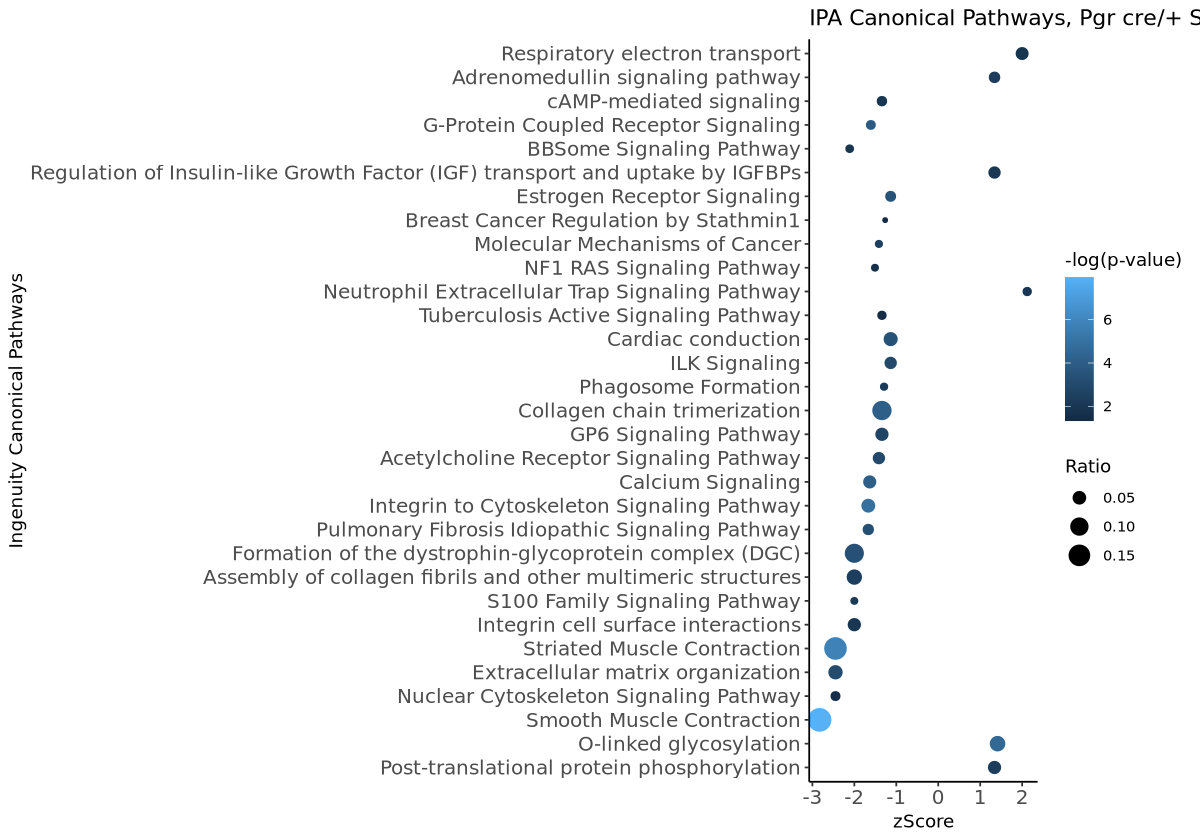

In [3]:
## Make dot plots for GO terms.

# Make the function for GO plots. See the Github link above.
# Code taken from enrichplot: https://github.com/YuLab-SMU/enrichplot/blob/devel/R/dotplot.R#L200-L207
ipa_plot <- function(ipa_table, title) {
    tmp <- ipa_table #%>% arrange(desc(Category))
    tmp[["Ingenuity Canonical Pathways"]] <- ordered(tmp[["Ingenuity Canonical Pathways"]],
                                                     levels=rev(tmp[["Ingenuity Canonical Pathways"]]))
    return(ggplot(tmp,
                  aes(y = `Ingenuity Canonical Pathways`,
                      x = zScore,
                      size = Ratio,
                      color = `-log(p-value)`)) + geom_point() + theme_bw() +  theme(axis.line = element_line(colour = "black"),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank(),
    panel.border = element_blank(),
    panel.background = element_blank(),
                                                                                    axis.text=element_text(size=12)) +
                   ggtitle(title))
}


saved <- options(repr.plot.width = 10)
ipa_plot(relevant_pws_Srfdd_MyoPgrdd, "IPA Canonical Pathways, Pgr cre/+ Srf f/f and Myh11 cre/+ Pgr f/f")
options(saved)

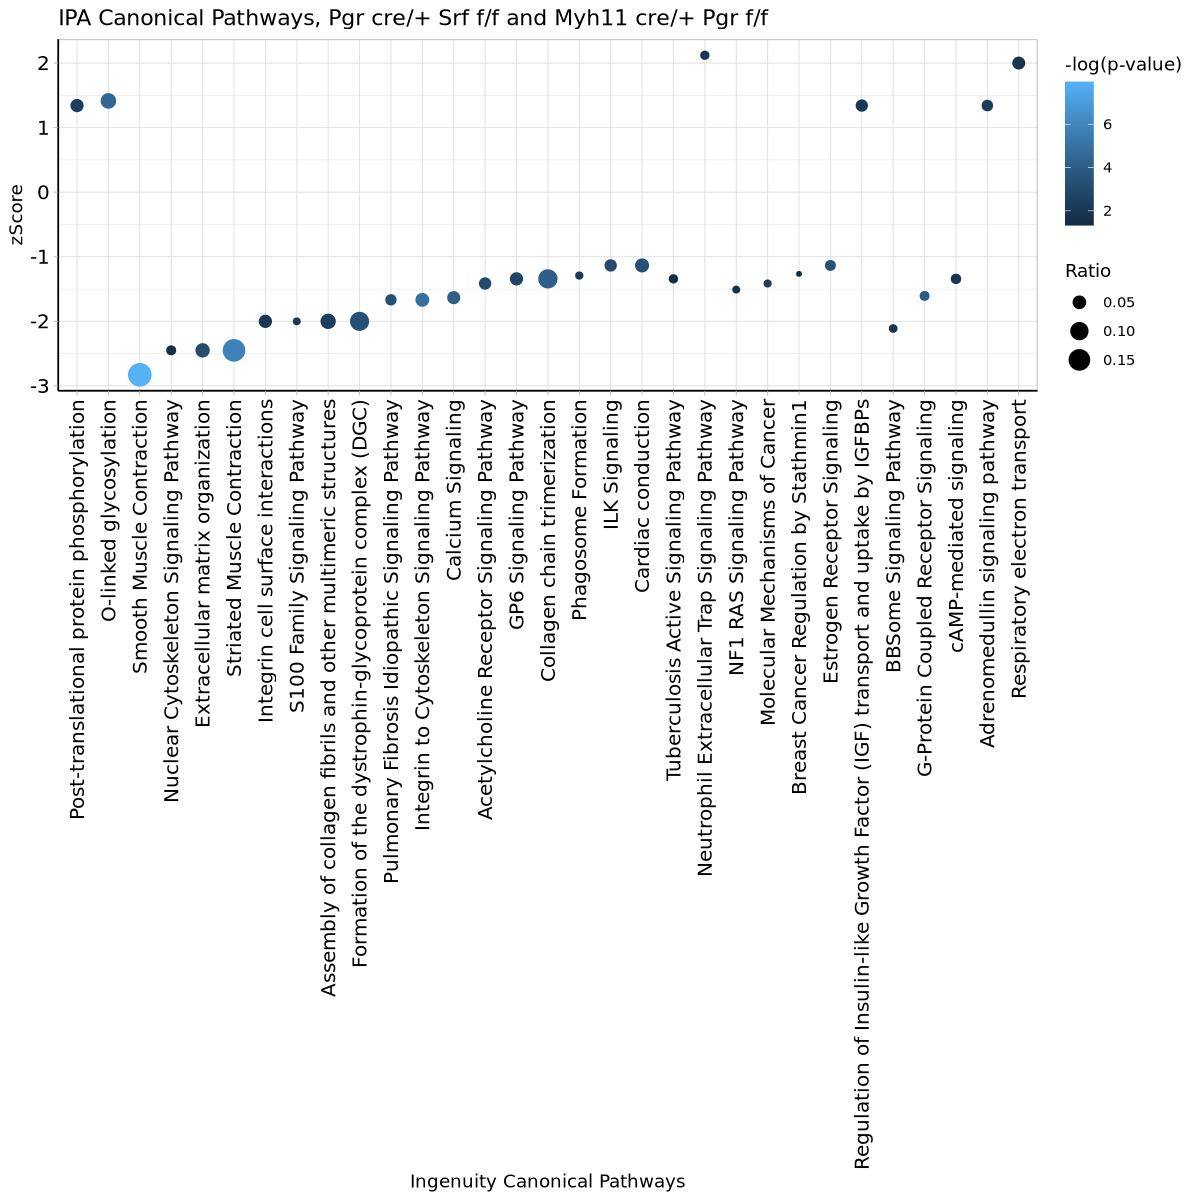

In [5]:
# Modify the layout and theme

ipa_plot <- function(ipa_table, title) {
    tmp <- ipa_table #%>% arrange(desc(Category))
    tmp[["Ingenuity Canonical Pathways"]] <- ordered(tmp[["Ingenuity Canonical Pathways"]],
                                                     levels=rev(tmp[["Ingenuity Canonical Pathways"]]))
    return(ggplot(tmp,
                  aes(y = zScore,
                      x = `Ingenuity Canonical Pathways`,
                      size = Ratio,
                      color = `-log(p-value)`)) + geom_point() + theme_light() +  theme(axis.line = element_line(colour = "black"),
    #panel.grid.major = element_blank(),
    #panel.grid.minor = element_blank(),
    #panel.border = element_blank(),
    #panel.background = element_blank(),
                axis.text.x=element_text(angle=90, hjust=1, vjust=0.5),
                axis.text=element_text(size=12, color="black")) +
                   ggtitle(title))
}


saved <- options(repr.plot.width = 10, repr.plot.height = 10)
ipa_plot(relevant_pws_Srfdd_MyoPgrdd, "IPA Canonical Pathways, Pgr cre/+ Srf f/f and Myh11 cre/+ Pgr f/f")
options(saved)

In [6]:
# Save plot as SVG

my_plot <- ipa_plot(relevant_pws_Srfdd_MyoPgrdd, "IPA Canonical Pathways, Pgr cre/+ Srf f/f and Myh11 cre/+ Pgr f/f")

    
ggsave(filename = "251216_Srfdd-MyoPgrdd_IPA.svg", plot = my_plot, 
           width = 10, height = 10, units = "in") 

In [7]:
sessionInfo()

R version 4.3.1 (2023-06-16)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Rocky Linux 8.10 (Green Obsidian)

Matrix products: default
BLAS/LAPACK: /ddn/gs1/home/marquardtrm/miniforge3/envs/r431/lib/libopenblasp-r0.3.30.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: America/New_York
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
[1] svglite_2.2.2     ggplot2_4.0.1     dplyr_1.1.4       data.table_1.17.8

loaded via a namespace (and not attached):
 [1] crayon_1.5.3       vctrs_0.6.5        cli_3.6.5          rlang_1.1.6  